# Support Vector Machine

In [ ]:
'''
- Does both regression and classification tasks.
- SVR and SVC
- It requires small set datasets.
- Model Parameters
    Kernel = (linear, rbf(default), poly)
            - rbf -> Radial Basis Function
    C = (0.01, 0.1, 1.0, 10, 100)
    gamma = (0.01, 0.1, 1.0, scale, 10)

-Stratify

'''


'\n- Does both regression and classification tasks.\n- SVR and SVC\n- It requires small set datasets.\n- Model Parameters\n    Kernel = (liblinear, rbf(default), poly)\n    C = (0.01, 0.1, 1.0, 10, 100)\n    gamma = (0.01, 0.1, 1.0, scale, 10)\n\n-Stratify\n\n'

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import SVM model
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix


In [15]:
df = pd.read_csv('Dataset/Cardiovascular_Disease.csv')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [16]:
df['age'] = df['age'] // 365
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0


In [17]:
filtered_df = df[
    (df['height'].between(150, 190))&
    (df['weight'].between(45, 110))&
    (df['ap_hi'].between(90, 180))&
    (df['ap_lo'].between(50, 90))
]

In [18]:
df_sample = filtered_df.sample(n= 6000, random_state=42)
df_sample

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
45845,65482,58,1,168,68.0,120,80,3,3,0,0,0,0
60877,86894,57,2,185,102.0,130,85,1,1,0,0,1,0
69901,99845,53,1,165,71.0,120,70,1,1,0,0,1,1
41468,59252,64,2,165,69.0,130,80,1,1,0,0,0,0
68951,98507,47,2,168,64.0,120,80,1,1,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
42364,60521,60,2,174,77.0,160,60,1,1,0,0,1,1
56506,80653,61,1,164,59.0,140,80,2,1,0,0,1,1
15438,22066,58,1,170,70.0,120,80,1,1,0,0,1,1
23485,33557,52,2,168,71.0,160,80,1,1,1,0,1,1


In [19]:
df_sample.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='str')

### Feature and Target

In [20]:
features= ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active']
target = 'cardio'

In [21]:
X = df_sample[features]
Y = df_sample[target]

### Train and Test Data

In [22]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

### Feature Scaling

In [23]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

### Model Implementation

In [30]:
model = SVC(
    kernel ='linear',
    C=1.0,
    gamma='scale'
)
model.fit(X_train_scale, Y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [31]:
Y_pred = model.predict(X_test_scale)
Y_pred

array([1, 0, 0, ..., 0, 1, 0], shape=(1200,))

In [32]:
cm = confusion_matrix(Y_test, Y_pred)
cr = classification_report(Y_test, Y_pred
                           )

In [33]:
print(cm)

[[542 105]
 [223 330]]


In [34]:
print(cr)

              precision    recall  f1-score   support

           0       0.71      0.84      0.77       647
           1       0.76      0.60      0.67       553

    accuracy                           0.73      1200
   macro avg       0.73      0.72      0.72      1200
weighted avg       0.73      0.73      0.72      1200



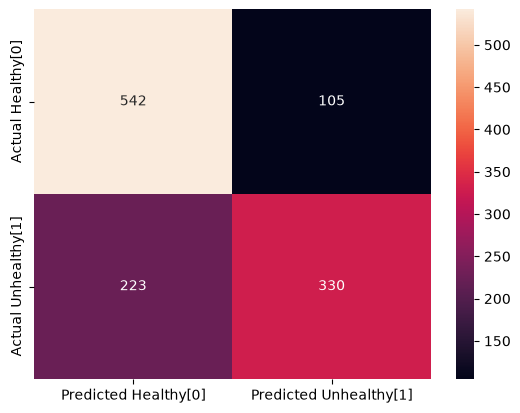

In [35]:
sns.heatmap(cm, annot=True, fmt='1.0f', xticklabels=['Predicted Healthy[0]', 'Predicted Unhealthy[1]'],
            yticklabels=['Actual Healthy[0]', 'Actual Unhealthy[1]'])
plt.show()

### New Data Prediction

In [36]:
data = {
    'age':[30, 45, 39],
    'gender':[1, 2, 1],
    'height':[151, 160, 157],
    'weight':[60, 70, 50],
    'ap_hi': [120, 140, 160],
    'ap_lo': [90, 80, 60],
    'cholesterol': [1, 3, 2],
    'gluc': [1, 1, 2],
    'smoke': [0, 1, 1],
    'alco': [1, 1, 1],
    'active':[0, 1, 0]
}

In [37]:
input_data = pd.DataFrame(data)
input_data

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active
0,30,1,151,60,120,90,1,1,0,1,0
1,45,2,160,70,140,80,3,1,1,1,1
2,39,1,157,50,160,60,2,2,1,1,0


In [38]:
inpute_scale = scaler.transform(input_data)
pred= model.predict(inpute_scale)
input_data['cardio_pred'] = pred

In [39]:
input_data

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio_pred
0,30,1,151,60,120,90,1,1,0,1,0,0
1,45,2,160,70,140,80,3,1,1,1,1,1
2,39,1,157,50,160,60,2,2,1,1,0,1
